In [1]:
from google.colab import drive
drive.mount("/content/drive")



Mounted at /content/drive


In [2]:
import torch
print("GPU Available:", torch.cuda.is_available())
!nvidia-smi

GPU Available: True
Sun Oct 11 09:14:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             14W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------------

In [3]:
import shutil, yaml
from pathlib import Path


In [4]:
base = Path("/content/drive/MyDrive/cv_project")
src = base / "roboflow_export"
dst = base / "dataset"


In [5]:
for old, new in [("train", "train"), ("valid", "val"), ("test", "test")]:
    for kind in ["images", "labels"]:
        out = dst / kind / new
        out.mkdir(parents=True, exist_ok=True)
        for f in (src / old / kind).glob("*"):
            shutil.copy(f, out / f.name)

In [8]:
names = yaml.safe_load(open(src / "data.yaml"))["names"]
cfg = {
    "path": str(dst),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": names,
}
yaml.dump(cfg, open(dst / "data.yaml", "w"), sort_keys=False)

In [9]:
print(open(dst / "data.yaml").read())
for s in ["train", "val", "test"]:
    print(s, len(list((dst / "images" / s).glob("*"))), "images")

path: /content/drive/MyDrive/cv_project/dataset
train: images/train
val: images/val
test: images/test
names:
- bus
- car
- motorcycle
- three-wheeler
- truck

train 175 images
val 50 images
test 25 images


In [10]:
!pip install -U ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 11.3 MB/s eta 0:00:00


In [11]:
import time
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

start = time.time()
results = model.train(
    data="/content/drive/MyDrive/cv_project/dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=8,
    pretrained=True,
    project="/content/drive/MyDrive/cv_project/outputs/training_results",
    name="yolov8n_baseline",
)
mins = (time.time() - start) / 60
print(f"Training time: {mins:.1f} minutes")
print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/cv_project/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchs

In [12]:
import shutil
from pathlib import Path

models_dir = Path("/content/drive/MyDrive/cv_project/models")
models_dir.mkdir(exist_ok=True)
best = Path("/content/drive/MyDrive/cv_project/outputs/training_results/yolov8n_baseline/weights/best.pt")
shutil.copy(best, models_dir / "best.pt")
print("Saved:", models_dir / "best.pt")

Saved: /content/drive/MyDrive/cv_project/models/best.pt


In [13]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/cv_project/models/best.pt")
metrics = model.val(
    data="/content/drive/MyDrive/cv_project/dataset/data.yaml",
    split="test",
    project="/content/drive/MyDrive/cv_project/outputs/training_results",
    name="test_eval",
)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP@0.5:", metrics.box.map50)
print("mAP@0.5:0.95:", metrics.box.map)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 55.1±13.4 MB/s, size: 50.7 KB)
val: Scanning /content/drive/MyDrive/cv_project/dataset/labels/test... 25 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 25/25 109.4it/s 0.2s
val: New cache created: /content/drive/MyDrive/cv_project/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.1it/s 1.8s
                   all         25        192      0.586      0.458      0.476      0.274
                   bus         12         46      0.868      0.261      0.437      0.237
                   car         15         80      0.698      0.537      0.524      0.315
            motorcycle          5          6      0.348      0.359      0.318      0.109
         three-wheeler         12         3

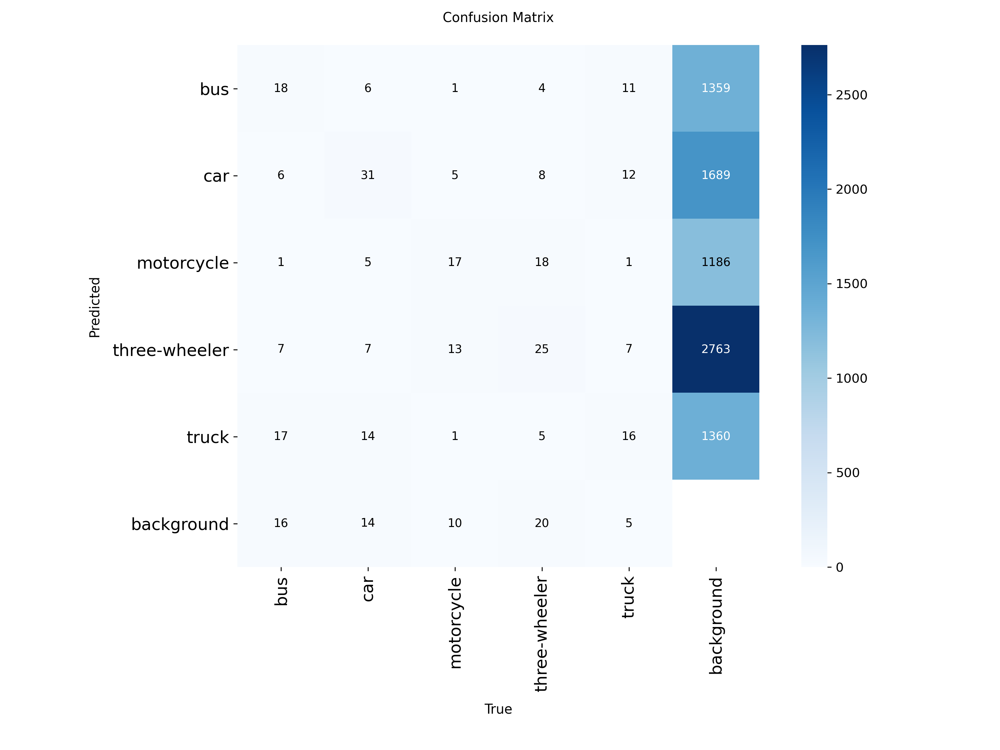

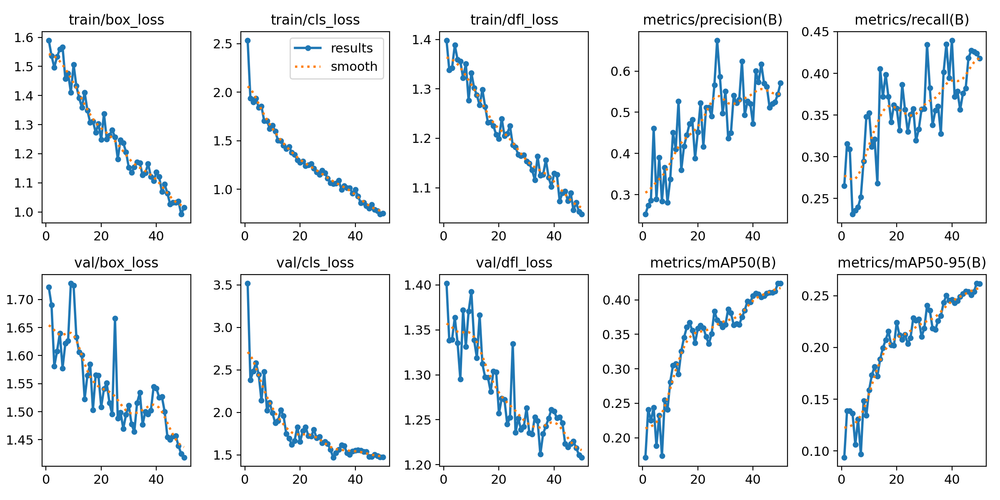

In [14]:
from IPython.display import Image, display
d = "/content/drive/MyDrive/cv_project/outputs/training_results/yolov8n_baseline/"
for f in ["confusion_matrix.png", "results.png"]:
    display(Image(d + f))


image 1/25 /content/drive/MyDrive/cv_project/dataset/images/test/135_jpg.rf.8e8044525bde197e07cb237eb69199b3.jpg: 640x640 1 bus, 1 car, 2 three-wheelers, 24.9ms
image 2/25 /content/drive/MyDrive/cv_project/dataset/images/test/179_jpg.rf.9ef5b1db0058cc426a356b30ca60ef83.jpg: 640x640 2 trucks, 24.2ms
image 3/25 /content/drive/MyDrive/cv_project/dataset/images/test/212_jpg.rf.554380da46f909bb82892334f0464c70.jpg: 640x640 15 cars, 6 three-wheelers, 4 trucks, 20.4ms
image 4/25 /content/drive/MyDrive/cv_project/dataset/images/test/Asraf_12_jpg.rf.47fe0a1896914dfd28c09899275a74d6.jpg: 640x640 1 bus, 2 cars, 1 three-wheeler, 25.2ms
image 5/25 /content/drive/MyDrive/cv_project/dataset/images/test/Asraf_41_jpg.rf.035e57338b58c6e1cec1e8c4d2a85fa7.jpg: 640x640 1 bus, 1 car, 2 three-wheelers, 1 truck, 38.2ms
image 6/25 /content/drive/MyDrive/cv_project/dataset/images/test/Dipto_-333_jpg.rf.0da22366820c6f0b5b3981bd14d2b28d.jpg: 640x640 1 bus, 1 truck, 51.8ms
image 7/25 /content/drive/MyDrive/cv_pro

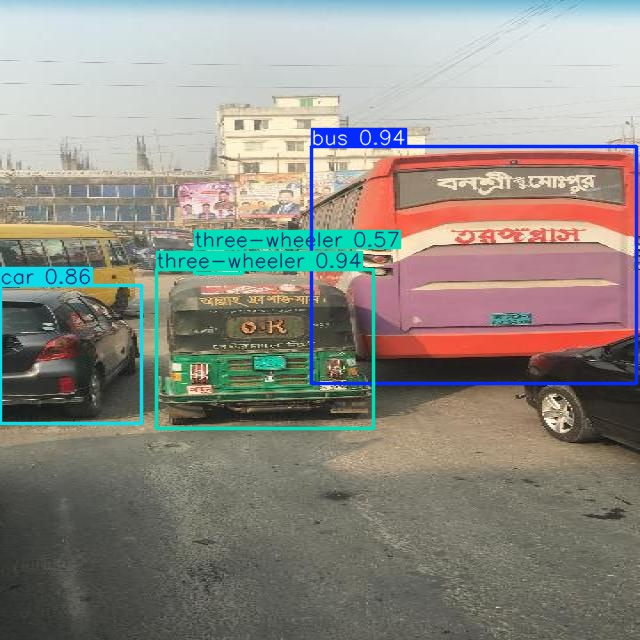

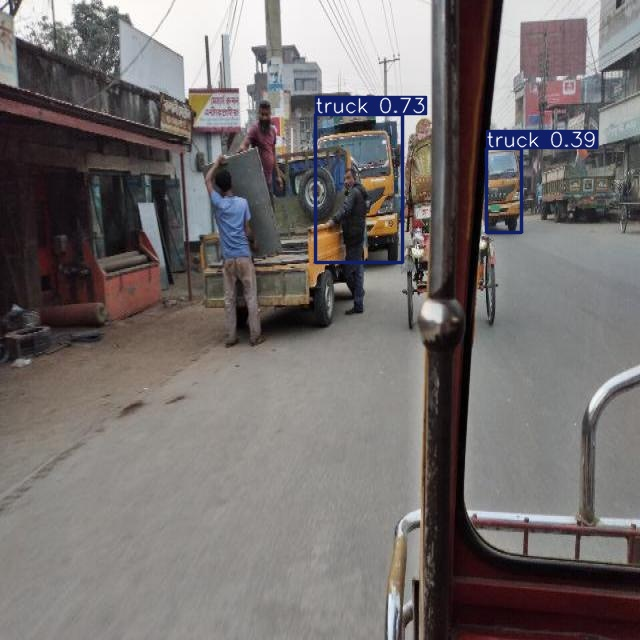

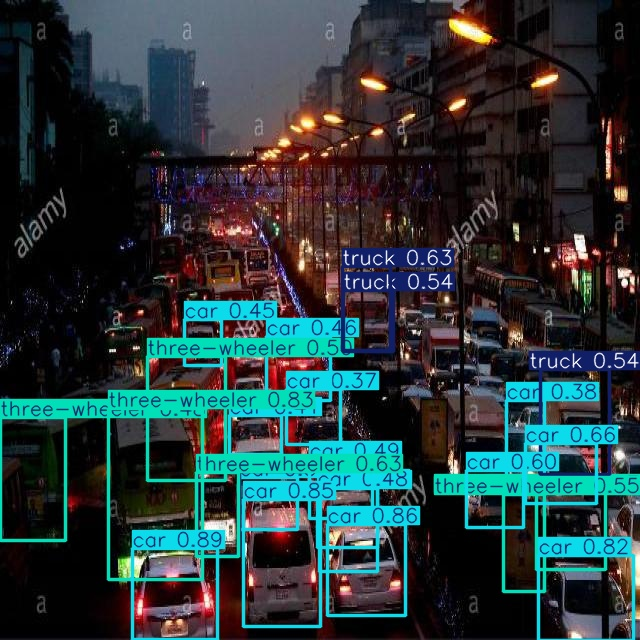

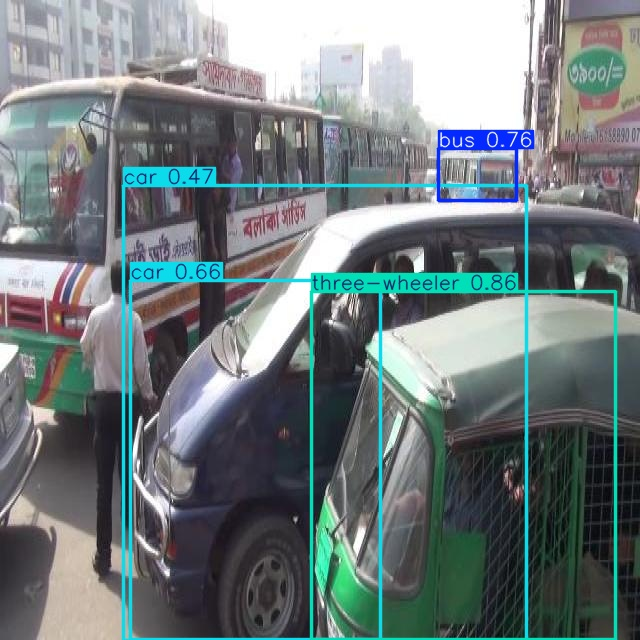

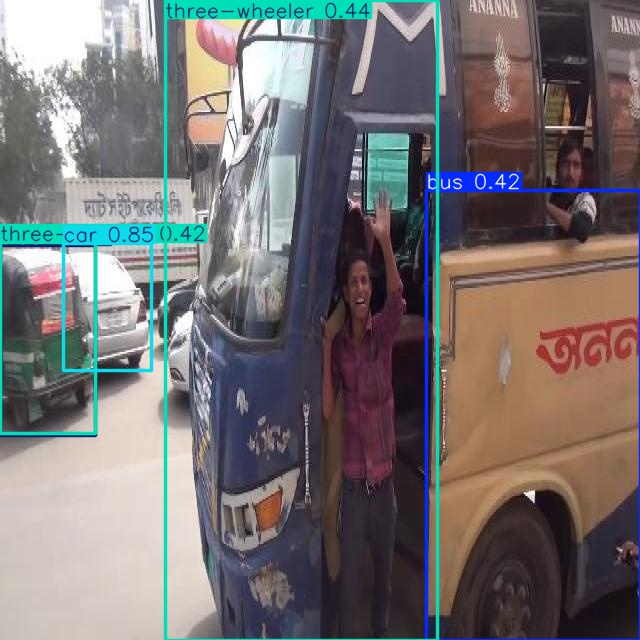

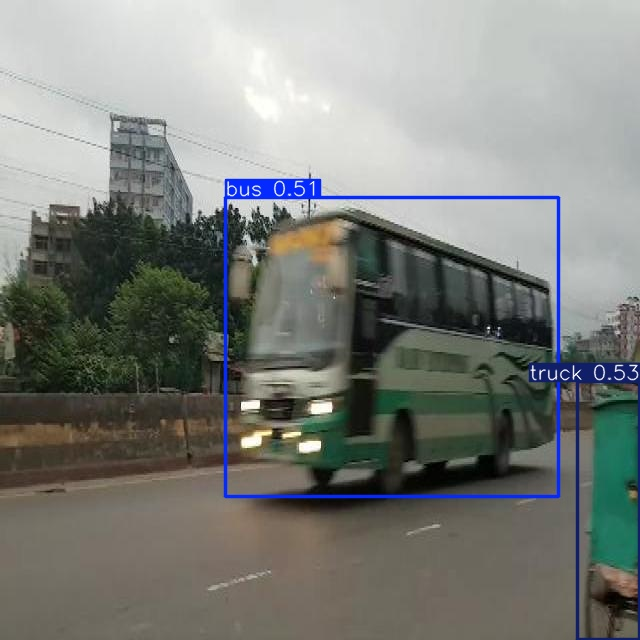

In [15]:
results = model.predict(
    source="/content/drive/MyDrive/cv_project/dataset/images/test",
    conf=0.35,
    save=True,
    project="/content/drive/MyDrive/cv_project/outputs/predictions",
    name="test_predictions",
)

import glob
from IPython.display import Image, display
for f in sorted(glob.glob("/content/drive/MyDrive/cv_project/outputs/predictions/test_predictions/*.jpg"))[:6]:
    display(Image(f))

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 59.6±12.0 MB/s, size: 56.4 KB)
val: Scanning /content/drive/MyDrive/cv_project/dataset/labels/val.cache... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 11.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.1it/s 3.7s
                   all         50        321       0.53      0.446      0.365      0.233
                   bus         33         65      0.509      0.431      0.368      0.256
                   car         29         77      0.523      0.597      0.487      0.334
            motorcycle         23         47      0.576      0.404      0.322      0.138
         three-wheeler         27         80      0.519      0.338      0.273      0.177
                 truck         27

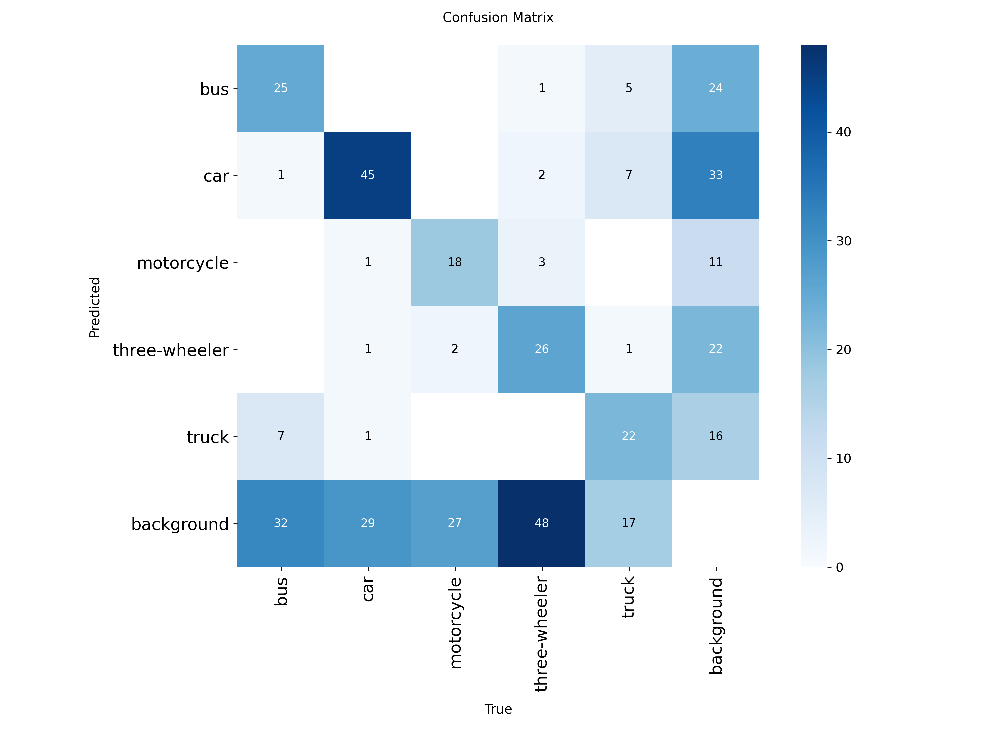

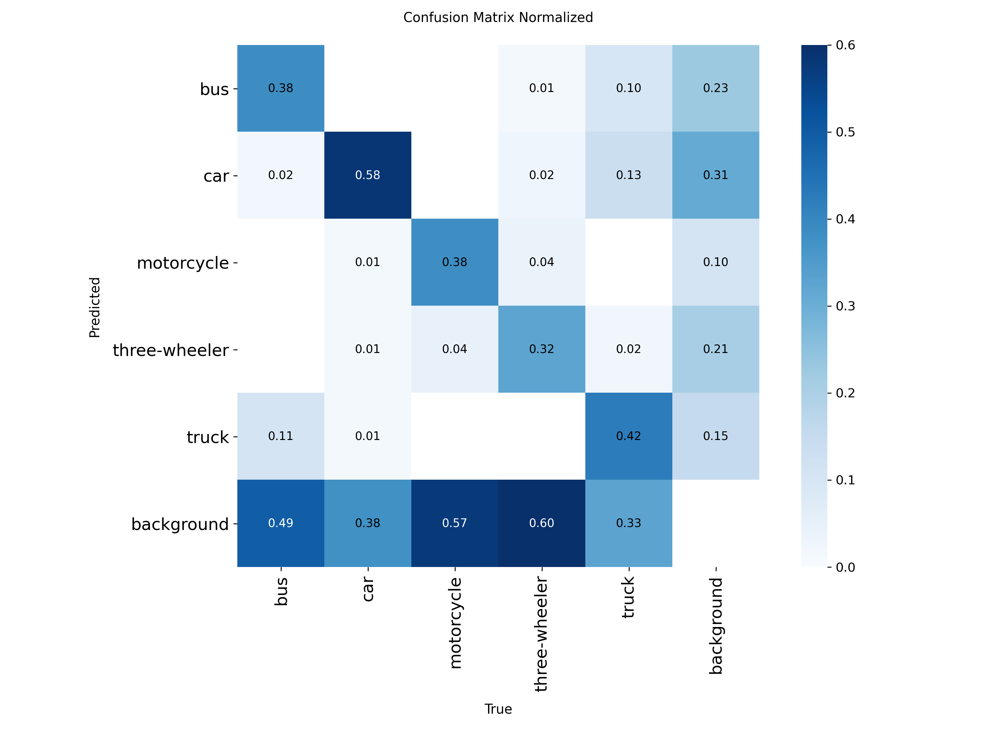

In [16]:
from ultralytics import YOLO
from IPython.display import Image, display

model = YOLO("/content/drive/MyDrive/cv_project/models/best.pt")
model.val(
    data="/content/drive/MyDrive/cv_project/dataset/data.yaml",
    conf=0.25,
    plots=True,
    project="/content/drive/MyDrive/cv_project/outputs/training_results",
    name="val_conf025",
)

d = "/content/drive/MyDrive/cv_project/outputs/training_results/val_conf025/"
display(Image(d + "confusion_matrix.png"))
display(Image(d + "confusion_matrix_normalized.png"))

In [17]:
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/cv_project/models/best.pt")
names = model.names
base = Path("/content/drive/MyDrive/cv_project/dataset")
split = "test"   # zyada candidates chahiyen to "val" bhi chala sakte ho

def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    ua = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / ua if ua > 0 else 0

rows = []
for img in sorted((base/"images"/split).glob("*.jpg")):
    r = model.predict(str(img), conf=0.35, verbose=False)[0]
    h, w = r.orig_shape
    gts = []
    for l in (base/"labels"/split/(img.stem + ".txt")).read_text().splitlines():
        if l.strip():
            c, x, y, bw, bh = l.split()
            c = int(c); x, y, bw, bh = map(float, (x, y, bw, bh))
            gts.append((c, [(x-bw/2)*w, (y-bh/2)*h, (x+bw/2)*w, (y+bh/2)*h]))
    preds = [(int(b.cls[0]), b.xyxy[0].tolist()) for b in r.boxes]

    used, ok, missed, wrong, notes = set(), 0, 0, 0, []
    for c, gb in gts:
        best, best_iou = -1, 0
        for j, (pc, pb) in enumerate(preds):
            if j in used:
                continue
            v = iou(gb, pb)
            if v > best_iou:
                best, best_iou = j, v
        if best >= 0 and best_iou >= 0.5:
            used.add(best)
            if preds[best][0] == c:
                ok += 1
            else:
                wrong += 1
                notes.append(f"{names[c]} -> {names[preds[best][0]]}")
        else:
            missed += 1
            notes.append(f"missed {names[c]}")
    fp = len(preds) - len(used)
    rows.append(dict(image=img.name[:30], gt=len(gts), correct=ok, missed=missed,
                     wrong_class=wrong, false_pos=fp, notes="; ".join(notes)))

df = pd.DataFrame(rows)
df["problems"] = df.missed + df.wrong_class + df.false_pos
df = df.sort_values("problems", ascending=False)
df.to_csv("/content/drive/MyDrive/cv_project/outputs/error_candidates.csv", index=False)
display(df.head(15))

,image,gt,correct,missed,wrong_class,false_pos,notes,problems
2,212_jpg.rf.554380da46f909bb828,58,11,45,2,12,bus -> three-wheeler; missed bus; missed bus; ...,59
23,Pias-322-_jpg.rf.c9c5b8c59af80,16,7,8,1,1,missed truck; missed three-wheeler; missed thr...,10
16,Navid_62_jpg.rf.b00cb9dee34b3d,5,3,2,0,8,missed bus; missed motorcycle,10
3,Asraf_12_jpg.rf.47fe0a1896914d,10,2,7,1,1,truck -> car; missed car; missed bus; missed b...,9
6,Dipto_-57_jpg.rf.9b8df7e58be80,8,4,2,2,4,truck -> car; three-wheeler -> truck; missed c...,8
22,Pias-191-_jpg.rf.637a97727ecb8,7,5,2,0,6,missed motorcycle; missed car,8
21,Numan_-383-_jpg.rf.7707f33048d,6,1,4,1,1,bus -> truck; missed car; missed car; missed b...,6
4,Asraf_41_jpg.rf.035e57338b58c6,6,2,3,1,2,missed truck; missed car; missed car; bus -> t...,6
13,Navid_470_jpg.rf.b15d4cf5c4f26,9,5,4,0,1,missed car; missed truck; missed car; missed car,5
12,Navid_467_jpg.rf.94558d904fb2f,9,4,5,0,0,missed truck; missed three-wheeler; missed mot...,5


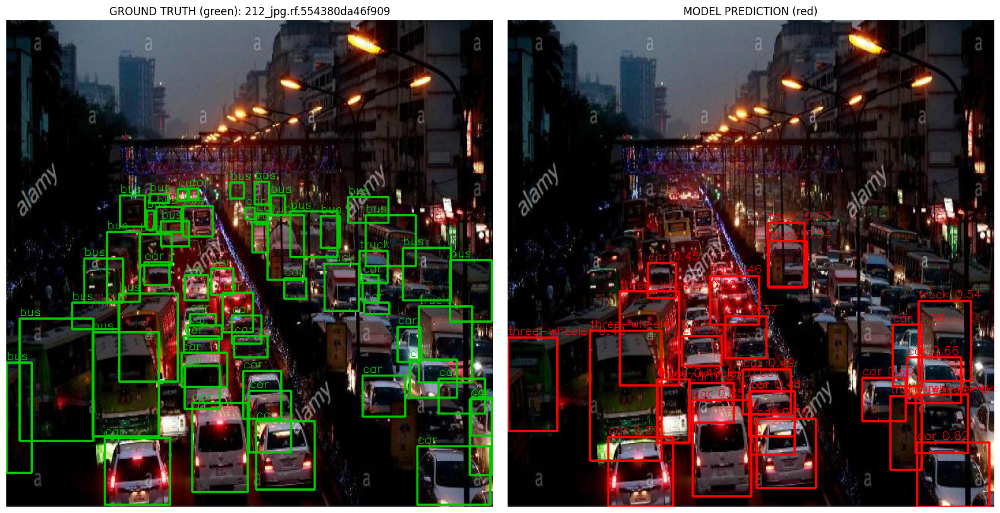

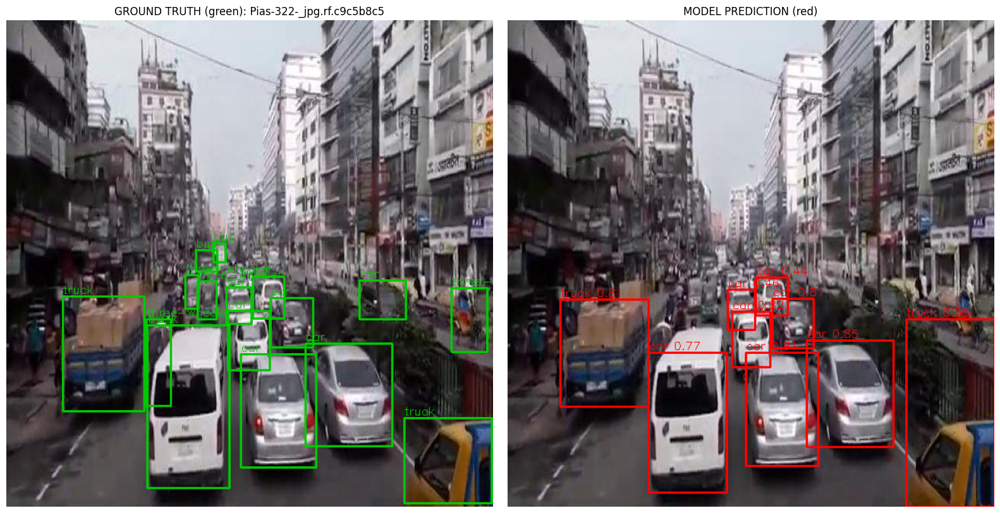

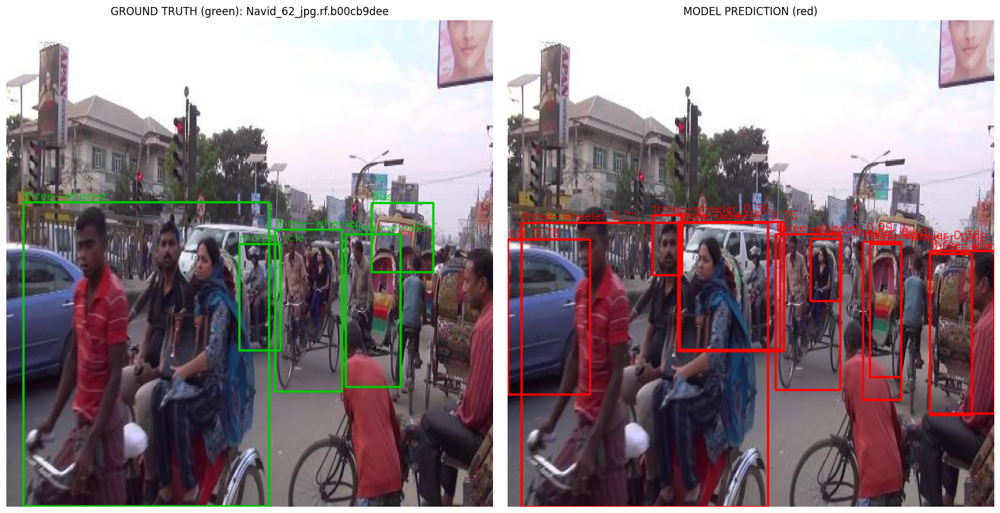

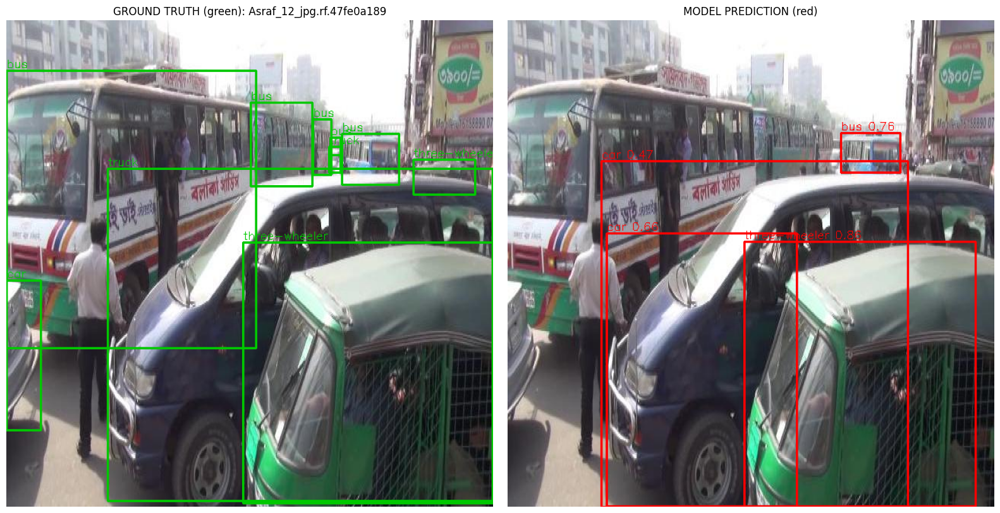

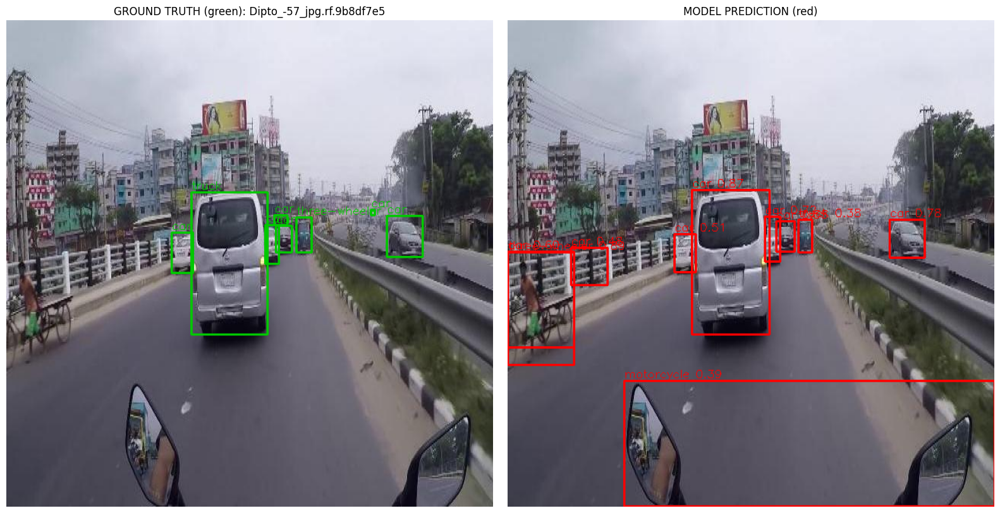

...

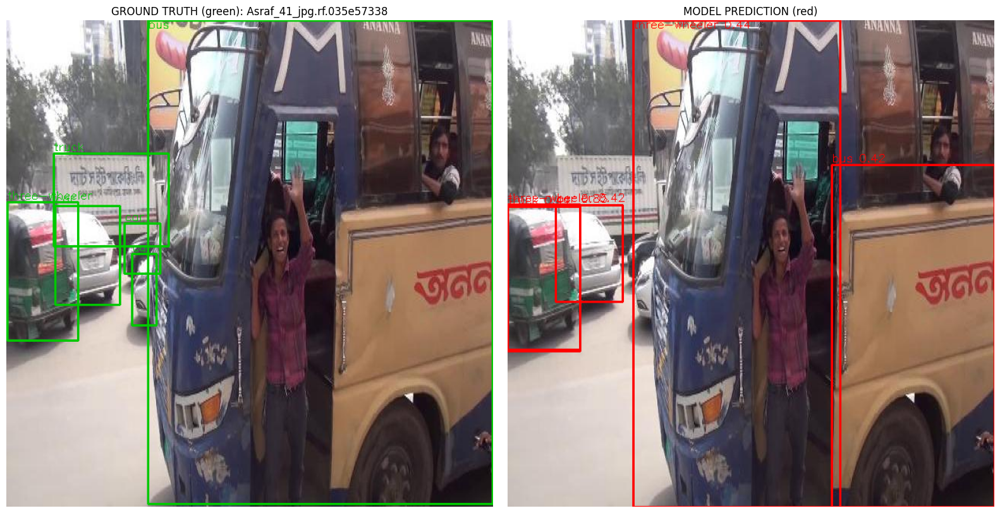

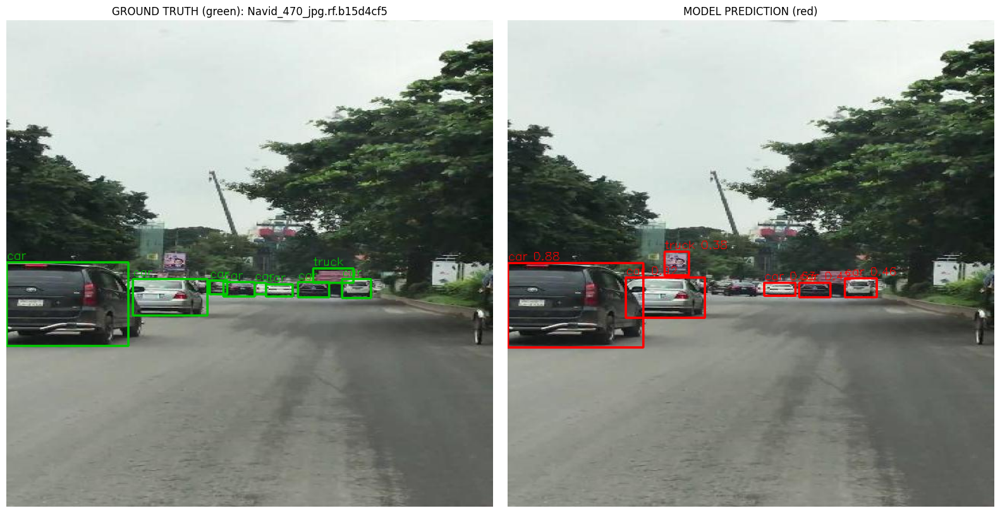

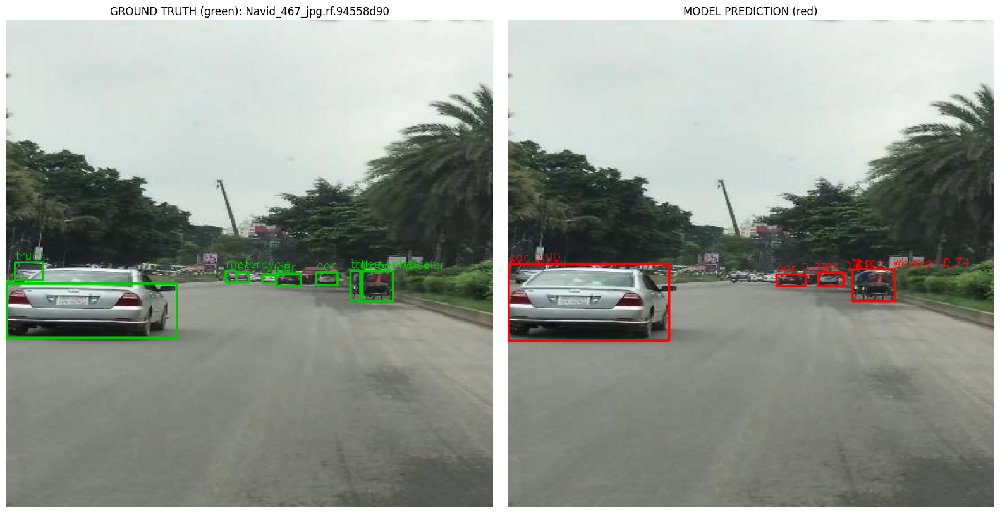

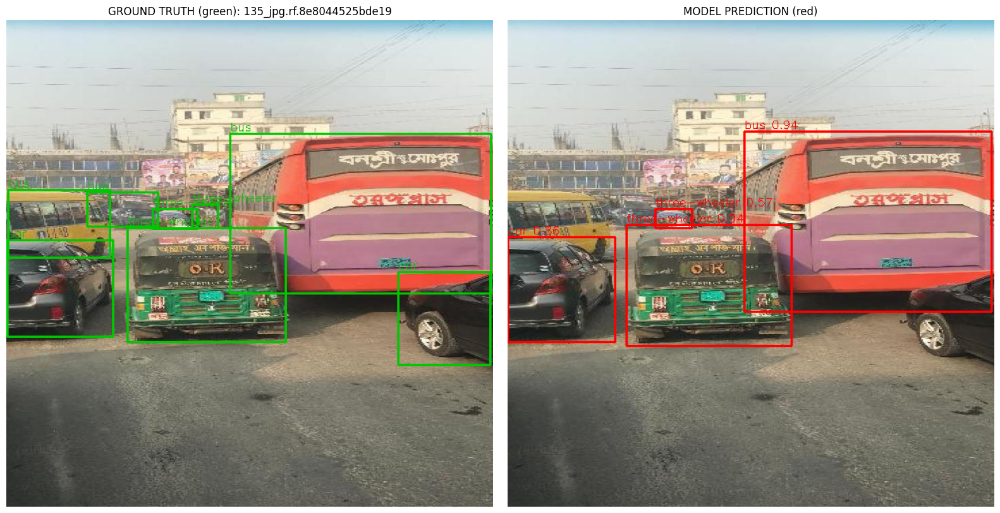

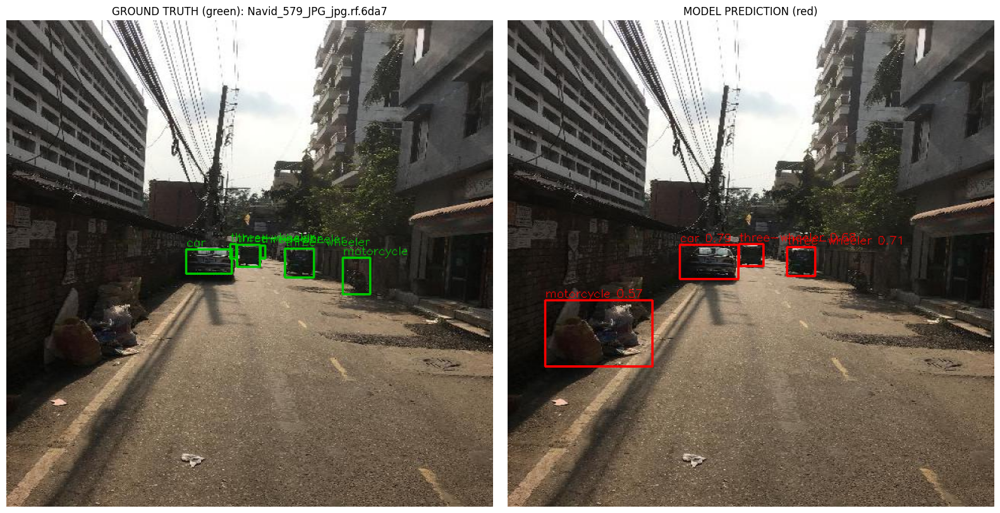

In [18]:
import cv2, matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/cv_project/models/best.pt")
names = model.names
base = Path("/content/drive/MyDrive/cv_project/dataset")
split = "test"
FONT = cv2.FONT_HERSHEY_SIMPLEX

picks = ["212_jpg", "Pias-322", "Navid_62", "Asraf_12", "Dipto_-57", "Pias-191",
         "Numan_-383", "Asraf_41", "Navid_470", "Navid_467", "135_jpg", "Navid_579"]

out = Path("/content/drive/MyDrive/cv_project/outputs/error_analysis")
out.mkdir(parents=True, exist_ok=True)

for p in picks:
    img_path = next((base / "images" / split).glob(p + "*"))
    im = cv2.imread(str(img_path)); h, w = im.shape[:2]
    gt, pr = im.copy(), im.copy()

    for l in (base / "labels" / split / (img_path.stem + ".txt")).read_text().splitlines():
        if not l.strip():
            continue
        c, x, y, bw, bh = l.split(); c = int(c)
        x, y, bw, bh = map(float, (x, y, bw, bh))
        x1, y1, x2, y2 = int((x-bw/2)*w), int((y-bh/2)*h), int((x+bw/2)*w), int((y+bh/2)*h)
        cv2.rectangle(gt, (x1, y1), (x2, y2), (0, 200, 0), 2)
        cv2.putText(gt, names[c], (x1, max(y1-4, 10)), FONT, 0.5, (0, 200, 0), 1)

    r = model.predict(str(img_path), conf=0.35, verbose=False)[0]
    for b in r.boxes:
        x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
        cv2.rectangle(pr, (x1, y1), (x2, y2), (0, 0, 255), 2)
        cv2.putText(pr, f"{names[int(b.cls[0])]} {float(b.conf[0]):.2f}", (x1, max(y1-4, 10)), FONT, 0.5, (0, 0, 255), 1)

    fig, ax = plt.subplots(1, 2, figsize=(16, 8))
    ax[0].imshow(cv2.cvtColor(gt, cv2.COLOR_BGR2RGB)); ax[0].set_title(f"GROUND TRUTH (green): {img_path.name[:25]}")
    ax[1].imshow(cv2.cvtColor(pr, cv2.COLOR_BGR2RGB)); ax[1].set_title("MODEL PREDICTION (red)")
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.savefig(out / f"{p}.png", dpi=100)
    plt.show()

In [20]:
from pathlib import Path
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/cv_project/models/best.pt")
names = model.names

name = "Navid_62"   # <-- yahan us image ka naam likho jise check karna hai
img = next(Path("/content/drive/MyDrive/cv_project/dataset/images/test").glob(name + "*"))
print("Image:", img.name)

r = model.predict(str(img), conf=0.1, verbose=False)[0]
for b in sorted(r.boxes, key=lambda b: -float(b.conf[0])):
    print(names[int(b.cls[0])], round(float(b.conf[0]), 2))

Image: Navid_62_jpg.rf.b00cb9dee34b3d9b98e53125dd6e1974.jpg
three-wheeler 0.99
car 0.78
three-wheeler 0.75
three-wheeler 0.75
three-wheeler 0.71
three-wheeler 0.68
truck 0.54
three-wheeler 0.52
three-wheeler 0.43
three-wheeler 0.36
three-wheeler 0.36
three-wheeler 0.34
three-wheeler 0.29
truck 0.27
three-wheeler 0.26
three-wheeler 0.25
truck 0.25
bus 0.21
three-wheeler 0.18
three-wheeler 0.18
car 0.18
three-wheeler 0.17
three-wheeler 0.16
three-wheeler 0.15
three-wheeler 0.12


In [21]:
import time
from ultralytics import YOLO

model_s = YOLO("yolov8s.pt")
start = time.time()
res_s = model_s.train(
    data="/content/drive/MyDrive/cv_project/dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=8,
    pretrained=True,
    project="/content/drive/MyDrive/cv_project/outputs/training_results",
    name="yolov8s_experiment",
)
print(f"Training time: {(time.time()-start)/60:.1f} minutes")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/cv_project/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_experiment, nbs=64, nms=None, o

In [22]:
import pandas as pd
from ultralytics import YOLO

base = "/content/drive/MyDrive/cv_project"
runs = {
    "yolov8n (baseline)": f"{base}/outputs/training_results/yolov8n_baseline/weights/best.pt",
    "yolov8s": f"{base}/outputs/training_results/yolov8s_experiment/weights/best.pt",
}

rows = []
for name, w in runs.items():
    m = YOLO(w)
    for split in ["val", "test"]:
        r = m.val(data=f"{base}/dataset/data.yaml", split=split, verbose=False, plots=False)
        rows.append({"model": name, "split": split,
                     "precision": round(r.box.mp, 3), "recall": round(r.box.mr, 3),
                     "mAP50": round(r.box.map50, 3), "mAP50-95": round(r.box.map, 3)})

df = pd.DataFrame(rows)
display(df)
df.to_csv(f"{base}/outputs/model_comparison.csv", index=False)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 55.8±16.4 MB/s, size: 56.8 KB)
val: Scanning /content/drive/MyDrive/cv_project/dataset/labels/val.cache... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 11.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.5it/s 1.6s
                   all         50        321      0.545      0.426      0.424      0.261
Speed: 2.6ms preprocess, 7.0ms inference, 0.0ms loss, 3.1ms postprocess per image
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 1.1±1.7 ms, read: 26.9±7.3 MB/s, size: 51.0 KB). Use local storage instead of remote/mounted 

,model,split,precision,recall,mAP50,mAP50-95
0,yolov8n (baseline),val,0.545,0.426,0.424,0.261
1,yolov8n (baseline),test,0.586,0.458,0.476,0.274
2,yolov8s,val,0.602,0.393,0.417,0.261
3,yolov8s,test,0.594,0.431,0.463,0.263


In [26]:
!ffmpeg -y -i "/content/drive/MyDrive/cv_project/demo_input/13926765_3840_2160_24fps.mp4" -vf scale=1280:-2 -an "/content/drive/MyDrive/cv_project/demo_input/demo_720p.mp4"

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [25]:
!ls -la "/content/drive/MyDrive/cv_project/"
!ls -la "/content/drive/MyDrive/cv_project/demo_input/"

total 28
drwx------ 7 root root 4096 Oct 11 09:31 .
drwx------ 9 root root 4096 Oct 11 09:13 ..
drwx------ 4 root root 4096 Oct 11 09:20 dataset
drwx------ 2 root root 4096 Oct 11 10:54 demo_input
drwx------ 2 root root 4096 Oct 11 09:31 models
drwx------ 5 root root 4096 Oct 11 10:30 outputs
drwx------ 5 root root 4096 Oct 11 09:04 roboflow_export
total 64470
drwx------ 2 root root     4096 Oct 11 10:54 .
drwx------ 7 root root     4096 Oct 11 09:31 ..
-rw------- 1 root root 66008383 Oct 11 10:46 13926765_3840_2160_24fps.mp4


In [27]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/cv_project/models/best.pt")
results = model.predict(
    source="/content/drive/MyDrive/cv_project/demo_input/demo_720p.mp4",
    conf=0.35,
    save=True,
    project="/content/drive/MyDrive/cv_project/outputs/demo_results",
    name="video_demo",
)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/681) /content/drive/MyDrive/cv_project/demo_input/demo_720p.mp4: 384x640 4 cars, 1 three-wheeler, 2 trucks, 13.5ms
video 1/1 (frame 2/681) /content/drive/MyDrive/cv_project/demo_input/demo_720p.mp4: 384x640 4 cars, 2 trucks, 23.8ms
video 1/1 (frame 3/681) /content/drive/MyDrive/cv_project/demo_input/demo_720p.mp4: 384x640 1 bus, 3 cars, 22.7ms
video 1/1 (frame 4/681) /content/drive/MyDrive/cv_project/demo_input/demo_720p.mp4: 384x640 1 

In [28]:
!ls -la "/content/drive/MyDrive/cv_project/outputs/demo_results/video_demo/"

total 125594
drwx------ 2 root root      4096 Oct 11 10:59 .
drwx------ 3 root root      4096 Oct 11 10:58 ..
-rw------- 1 root root 128599634 Oct 11 10:59 demo_720p.avi


In [31]:
!ffmpeg -y -i "/content/drive/MyDrive/cv_project/outputs/demo_results/video_demo/demo_720p.avi" -vcodec libx264 -crf 26 -preset fast -pix_fmt yuv420p "/content/drive/MyDrive/cv_project/outputs/demo_results/video_demo/demo_720p_out.mp4"
!ls -la "/content/drive/MyDrive/cv_project/outputs/demo_results/video_demo/"

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 54.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 9.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

image 1/1 /content/drive/MyDrive/cv_project/demo_input/Screenshot 2026-10-15 041029.png: 384x640 1 car, 8 trucks, 8.9ms
Speed: 82.2ms preprocess, 8.9ms inference, 33.3ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/runs/detect/predict
truck 0.71
truck 0.64
car 0.59
truck 0.51
truck 0.48
truck 0.44
truck 0.43
truck 0.43
truck 0.42


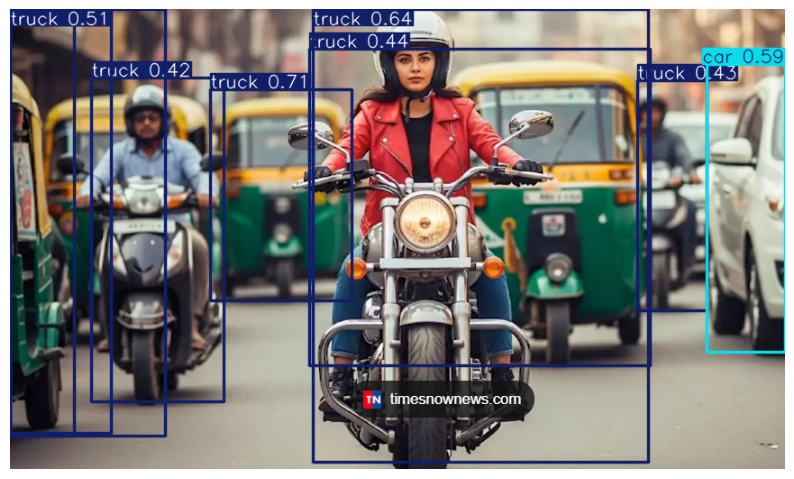

In [1]:
from google.colab import drive
drive.mount("/content/drive")
!pip install -q ultralytics

import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

m = YOLO("/content/drive/MyDrive/cv_project/models/best.pt")
r = m.predict("/content/drive/MyDrive/cv_project/demo_input/Screenshot 2026-10-15 041029.png", conf=0.35, save=True)

for b in r[0].boxes:
    print(m.names[int(b.cls[0])], round(float(b.conf[0]), 2))

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(r[0].plot(), cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()